<!-- # Copyright (c) 2026 takotime808 -->
# Benchmark Problems

`multioutreg.active.benchmarks` ships analytic test problems whose true answer is known everywhere.
They let you score a surrogate or an optimizer exactly instead of against a noisy hold-out set. This
tutorial lists them, takes a closer look at the multi-fidelity **AVT-331 L1 suite** of Mainini et al.
(2022), and shows how to score an optimizer with that paper's error metrics.

**What this tutorial covers:**

1. [The catalogue](#catalogue): every benchmark, its dimension, levels and costs
2. [The L1 multi-fidelity suite](#l1): the 14 problems and their fidelity levels
3. [Is a cheap level worth it?](#corr): correlation with the high fidelity, against cost
4. [Scoring an optimizer](#score): $\mathcal{E}_x$, $\mathcal{E}_f$, $\mathcal{E}_t$ and the normalized RMSE during a run
5. [Three things to watch](#pitfalls): noise, optimal sets that are not points, and several minimizers

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from multioutreg.active import (
    BENCHMARKS,
    L1_BENCHMARKS,
    ActiveLearner,
    MultiFidelityActiveLearner,
    get_benchmark,
)
from multioutreg.metrics import normalized_rmse
from multioutreg.surrogates import AdditiveCorrectionVFM, GaussianProcessSurrogate

warnings.filterwarnings("ignore")  # GP optimizer convergence chatter

BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
LEVEL_COLORS = {"hi": INK, "mid_hi": BLUE, "mid": BLUE, "mid_lo": AQUA, "lo": ORANGE}
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11,
    "axes.grid": True, "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

<a id="catalogue"></a>
## 1. The catalogue

`get_benchmark(name)` returns a `Benchmark`. Call it as `b(X, level)`, with `X` in the problem's
own bounds, to get one row per point. Levels are ordered **cheapest first**, and the last one,
`b.high`, is the high fidelity. The general-purpose problems are in `BENCHMARKS`. The
multi-fidelity ones there have a `"lo"` and a `"hi"` level with a 10× cost ratio, which you can
change with `cost_ratio=`.

In [2]:
def describe(name):
    b = get_benchmark(name, seed=0) if name in L1_BENCHMARKS else get_benchmark(name)
    n_out = b(b.sample(2, seed=0)).shape[1]
    return {"name": name, "inputs": b.n_features, "outputs": n_out, "levels": " / ".join(b.levels),
            "costs": " / ".join(f"{b.costs[l]:g}" for l in b.levels), "known minimum": b.minimum,
            "budget": b.budget}


pd.DataFrame([describe(n) for n in BENCHMARKS]).set_index("name").drop(columns="budget")

,inputs,outputs,levels,costs,known minimum
name,,,,,
forrester,1,1,lo / hi,1 / 10,-6.021
branin,2,1,hi,1,0.3979
currin,2,1,lo / hi,1 / 10,NaN
branin_currin,2,2,hi,1,NaN
ishigami,3,1,hi,1,NaN
hartmann3,3,1,hi,1,-3.863
park,4,1,lo / hi,1 / 10,NaN
borehole,8,1,lo / hi,1 / 10,NaN
branin_mf,2,1,lo / hi,1 / 10,0.3979


<a id="l1"></a>
## 2. The L1 multi-fidelity suite

`L1_BENCHMARKS` holds the 14 problems of Mainini et al., *Analytical Benchmark Problems for
Multifidelity Optimization Methods* ([arXiv:2204.07867](https://arxiv.org/abs/2204.07867)). They
were designed to stress multi-fidelity optimizers with localized and multimodal behaviour,
discontinuities, noise and growing dimension. Each one carries what the paper prescribes:

* **costs** as a fraction of one high-fidelity run, so `"hi"` costs 1
* a **budget** in high-fidelity equivalents
* the range of the high level: `minimum` and `maximum`
* the **optimum**: `argmin`, or `argmin_distance` when the optimal set is a face or a curve

The paper numbers levels from the top ($f_1$ is the highest fidelity). Here they are named from
the bottom:

| Levels | Names, cheapest first | Paper |
|---|---|---|
| 2 | `lo`, `hi` | $f_2$, $f_1$ |
| 3 | `lo`, `mid`, `hi` | $f_3$, $f_2$, $f_1$ |
| 4 (MF1.1 only) | `lo`, `mid_lo`, `mid_hi`, `hi` | $f_4$, $f_3$, $f_2$, $f_1$ |

The functions were written from the paper and checked against the reference optima the authors
publish with their code
([gitlab.com/qudo046/avt-331-l1-benchmarks](https://gitlab.com/qudo046/avt-331-l1-benchmarks)).
Where the paper's text and that code disagree, the code is followed.

In [3]:
l1 = pd.DataFrame([describe(n) for n in L1_BENCHMARKS]).set_index("name")
l1.insert(0, "problem", ["Forrester", "Jump Forrester"] + ["Rosenbrock"] * 3 + ["Shifted-rotated Rastrigin"] * 3
          + ["Heterogeneous"] * 3 + ["Springs", "Spring-masses", "Paciorek (noisy)"])
l1["maximum"] = [get_benchmark(n, seed=0).maximum for n in L1_BENCHMARKS]
l1.drop(columns="outputs")

,problem,inputs,levels,costs,known minimum,budget,maximum
name,,,,,,,
mf1.1,Forrester,1,lo / mid_lo / mid_hi / hi,0.05 / 0.1 / 0.5 / 1,-6.021,100,15.83
mf1.2,Jump Forrester,1,lo / hi,0.2 / 1,-0.9863,100,25.83
mf2.1,Rosenbrock,2,lo / mid / hi,0.1 / 0.5 / 1,0,200,3609
mf2.2,Rosenbrock,5,lo / mid / hi,0.1 / 0.5 / 1,0,500,1.444e+04
mf2.3,Rosenbrock,10,lo / mid / hi,0.1 / 0.5 / 1,0,1000,3.248e+04
mf3.1,Shifted-rotated Rastrigin,2,lo / mid / hi,0.00391 / 0.0625 / 1,0,200,4.02
mf3.2,Shifted-rotated Rastrigin,5,lo / mid / hi,0.00391 / 0.0625 / 1,0,500,10.05
mf3.3,Shifted-rotated Rastrigin,10,lo / mid / hi,0.00391 / 0.0625 / 1,0,1000,20.1
mf4.1,Heterogeneous,1,lo / hi,0.2 / 1,-0.625,100,0.3615


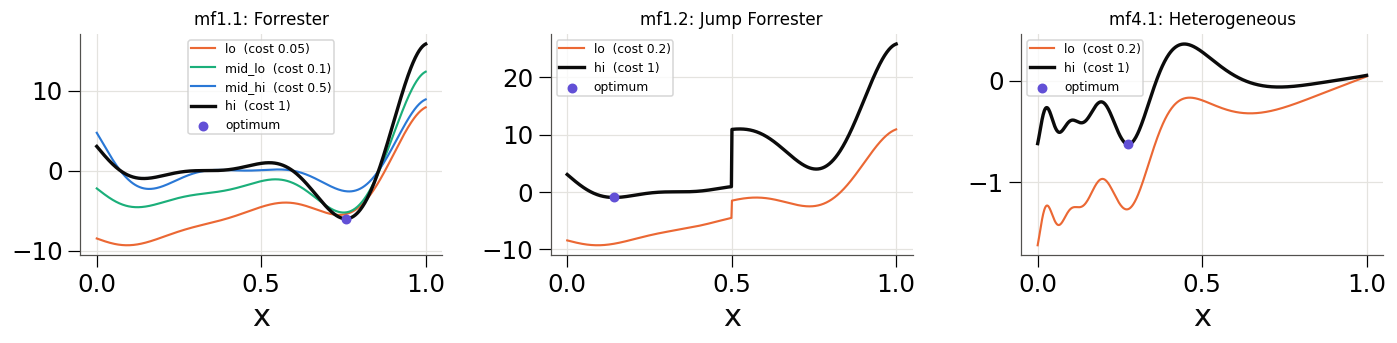

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, name, title in zip(axes, ["mf1.1", "mf1.2", "mf4.1"], ["Forrester", "Jump Forrester", "Heterogeneous"]):
    b = get_benchmark(name)
    x = np.linspace(*b.bounds[0], 600)[:, None]
    for lvl in b.levels:
        ax.plot(x, b(x, lvl), color=LEVEL_COLORS[lvl], lw=2.2 if lvl == "hi" else 1.4,
                label=f"{lvl}  (cost {b.costs[lvl]:g})")
    ax.scatter(b.argmin[:, 0], [b.minimum], color=VIOLET, zorder=5, s=30, label="optimum")
    ax.set(title=f"{name}: {title}", xlabel="x")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In 2-D the levels can differ in more than scale. Below are the high and low levels of the
shifted-rotated Rastrigin (MF3.1) and the noisy Paciorek (MF6). For MF6 the high level is shown
noise-free, using `b.true_value` (see [Section 5](#pitfalls)).

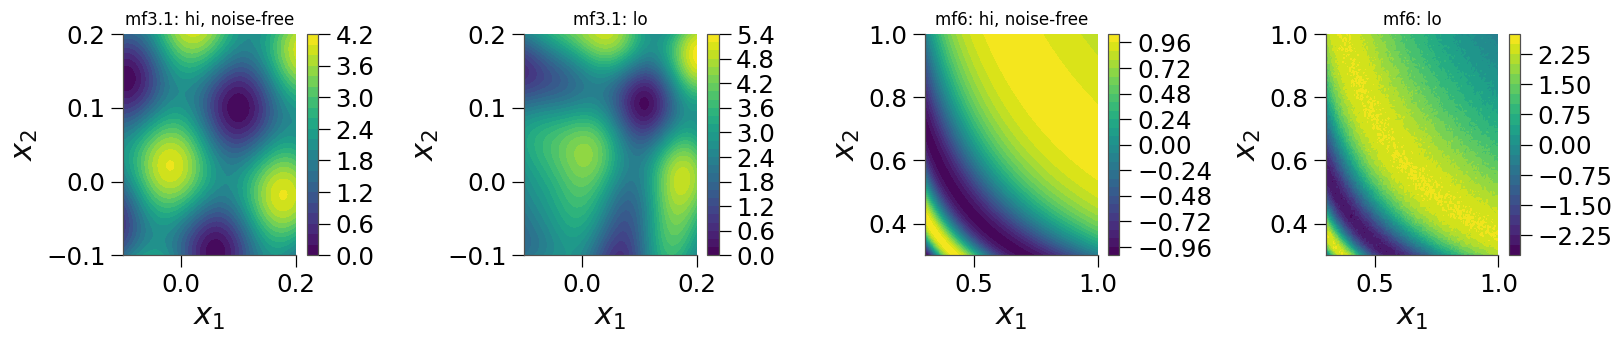

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for k, name in enumerate(["mf3.1", "mf6"]):
    b = get_benchmark(name, seed=0)
    g1, g2 = (np.linspace(*b.bounds[i], 150) for i in range(2))
    G = np.array(np.meshgrid(g1, g2)).reshape(2, -1).T
    for j, (label, Z) in enumerate([("hi, noise-free", b.true_value(G)), ("lo", b(G, "lo"))]):
        ax = axes[2 * k + j]
        cs = ax.contourf(g1, g2, Z.reshape(150, 150), levels=25, cmap="viridis")
        plt.colorbar(cs, ax=ax)
        ax.set(title=f"{name}: {label}", xlabel="$x_1$", ylabel="$x_2$")
        ax.grid(False)
plt.tight_layout()
plt.show()

<a id="corr"></a>
## 3. Is a cheap level worth it?

A lower level helps only if it predicts the high fidelity well and costs much less. The table
gives each lower level's correlation with `"hi"` over 4096 Sobol points, next to its cost. Most
are above 0.9. Four are not:

* MF6's low level ($r \approx 0.39$) carries six times the noise and a strong cosine bias.
* MF1.1's cheapest level, `lo` ($r \approx 0.74$), is affine in `"hi"` but adds a large linear
  trend. The two middle levels are much closer.
* MF4.1's low level ($r \approx 0.86$) is a bridge function whose scale changes with $x$.
* MF5.1's low level ($r \approx 0.88$) integrates the same ODE with a time step 60 times larger.

Those are the levels a multi-fidelity method has the least to gain from.

In [6]:
rows = []
for name in L1_BENCHMARKS:
    b = get_benchmark(name, seed=0)
    X = b.sample(4096, seed=0)
    hi = b.true_value(X).ravel()
    for lvl in b.levels[:-1]:
        rows.append({"name": name, "level": lvl, "cost": b.costs[lvl], "corr with hi": np.corrcoef(hi, b(X, lvl).ravel())[0, 1]})
pd.DataFrame(rows).set_index(["name", "level"])

cost  corr with hi
name  level                       
mf1.1 lo        0.05        0.7357
      mid_lo     0.1        0.9374
      mid_hi     0.5        0.9455
mf1.2 lo         0.2         0.962
mf2.1 lo         0.1        0.9982
      mid        0.5        0.9999
mf2.2 lo         0.1        0.9938
      mid        0.5        0.9999
mf2.3 lo         0.1        0.9812
      mid        0.5        0.9999
mf3.1 lo     0.00391        0.9377
      mid     0.0625        0.9722
mf3.2 lo     0.00391        0.9353
      mid     0.0625        0.9724
mf3.3 lo     0.00391        0.9337
      mid     0.0625        0.9726
mf4.1 lo         0.2        0.8643
mf4.2 lo         0.2        0.9465
mf4.3 lo         0.2        0.9569
mf5.1 lo      0.0167        0.8769
mf5.2 lo      0.0167        0.9878
mf6   lo         0.2        0.3893

<a id="score"></a>
## 4. Scoring an optimizer

Mainini et al. score a method by the estimated optimum $\hat x^\star$ it reports, with all
coordinates scaled to the unit cube:

$$\mathcal{E}_x = \frac{\lVert \hat x^\star - x^\star\rVert}{\sqrt{D}},\qquad
\mathcal{E}_f = \frac{f(\hat x^\star) - f_{\min}}{f_{\max} - f_{\min}},\qquad
\mathcal{E}_t = \sqrt{\tfrac12(\mathcal{E}_x^2 + \mathcal{E}_f^2)},$$

and the global accuracy of its surrogate by $\mathcal{E}_{\rm RMSE}$, the RMSE over the range
$f_{\max} - f_{\min}$. `b.optimum_errors(x_hat)` returns the first three. It evaluates
$f(\hat x^\star)$ with the true high level, not the surrogate's prediction.
`multioutreg.metrics.normalized_rmse` gives the fourth. For data that isn't a `Benchmark`, use
`design_error`, `goal_error`, `total_error` and `optimum_errors` from `multioutreg.metrics`.

Below, two optimizers run on MF4.1 (heterogeneous, 1-D) with the same budget of 30 high-fidelity
equivalents. This is a short run; the paper's budget is 100.

* **Single-fidelity EI**: `ActiveLearner` with expected improvement, on `"hi"` only.
* **Multi-fidelity EI**: `MultiFidelityActiveLearner` with an AR1 surrogate
  (`AdditiveCorrectionVFM`) and multi-fidelity EI, paying `b.costs` per run.

At every step $\hat x^\star$ is the minimizer of the surrogate mean on a dense grid.

In [7]:
b = get_benchmark("mf4.1")
BUDGET = 30
X_test = b.sample(1024, seed=1)
F_test = b.true_value(X_test)
grid = b.sample(4096, seed=2)


def score(model, cost):
    x_hat = grid[[np.argmin(np.asarray(model.predict(grid)).ravel())]]
    nrmse = normalized_rmse(F_test, model.predict(X_test), b.minimum, b.maximum)
    return {"cost": cost, **b.optimum_errors(x_hat), "NRMSE": nrmse}


sf_trace, mf_trace = [], []
sf = ActiveLearner(GaussianProcessSurrogate, b.bounds, acquisition="ei", random_state=0)
sf.run(b, n_init=4, n_iter=BUDGET - 4, callback=lambda L, rec: sf_trace.append(score(L.fit(), len(L.X_))))

mf = MultiFidelityActiveLearner(
    lambda: AdditiveCorrectionVFM(GaussianProcessSurrogate, GaussianProcessSurrogate),
    b.bounds, b.levels, b.costs, acquisition="ei", random_state=0,
)
mf.run({lvl: (lambda X, lvl=lvl: b(X, lvl)) for lvl in b.levels}, budget=BUDGET, X_test=X_test, Y_test=F_test,
       callback=lambda L, rec: mf_trace.append(score(L.fit(), L.total_spent)))

sf_trace, mf_trace = pd.DataFrame(sf_trace), pd.DataFrame(mf_trace)
print("multi-fidelity runs per level:", {lvl: len(v[0]) for lvl, v in mf.data_.items()})
pd.DataFrame({"single-fidelity EI": sf_trace.iloc[-1], "multi-fidelity EI": mf_trace.iloc[-1]}).T

multi-fidelity runs per level: {'lo': 45, 'hi': 21}


,cost,Ex,Ef,Et,NRMSE
single-fidelity EI,30,9.308e-05,1.222e-06,6.582e-05,0.01331
multi-fidelity EI,30,0.003574,0.001797,0.002828,0.116


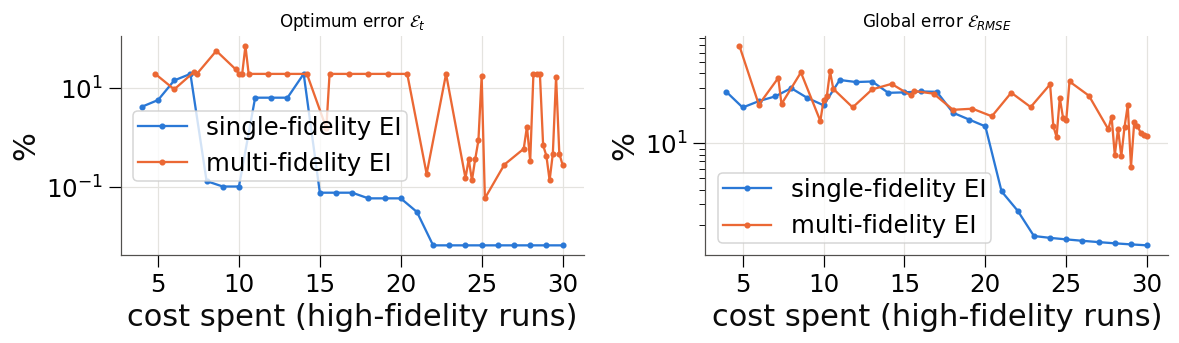

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, metric, title in zip(axes, ["Et", "NRMSE"], ["Optimum error $\\mathcal{E}_t$", "Global error $\\mathcal{E}_{RMSE}$"]):
    for trace, color, label in [(sf_trace, BLUE, "single-fidelity EI"), (mf_trace, ORANGE, "multi-fidelity EI")]:
        ax.plot(trace["cost"], 100 * np.maximum(trace[metric].abs(), 1e-8), color=color, marker="o", ms=3, label=label)
    ax.set(yscale="log", xlabel="cost spent (high-fidelity runs)", ylabel="%", title=title)
    ax.legend()
plt.tight_layout()
plt.show()

Here the high-fidelity-only run wins on both measures. This fits Section 3: MF4.1's cheap level is
one of the weakest in the suite, so the runs spent on it buy little. The same comparison on a
problem with a strongly correlated cheap level can come out the other way. The replication notebook
mentioned below runs it across the whole suite.

<a id="pitfalls"></a>
## 5. Three things to watch

**Noise (MF6).** `b(X)` returns a fresh noisy draw on every call (seed it with
`get_benchmark("mf6", seed=...)`). Score against `b.true_value(X)`, the noise-free high level.
`optimum_errors` already does this.

In [9]:
b6 = get_benchmark("mf6", seed=0)
x = np.array([[0.6, 0.7]])
print("noisy draws:", np.round([b6(x)[0, 0] for _ in range(4)], 4), " truth:", round(b6.true_value(x)[0, 0], 4))

noisy draws: [0.691  0.6877 0.6974 0.6907]  truth: 0.6894


**Optimal sets that are not points.** On MF4.2 and MF4.3 the whole face $x_1 = 0$ is optimal. On
MF6 the optima are two curves, $x_1 x_2 = 2/((3+4j)\pi)$. These benchmarks measure
$\mathcal{E}_x$ to the nearest point of the set (`argmin_distance`, or a dense `argmin`), so any
point on it scores zero.

In [10]:
b42 = get_benchmark("mf4.2")
pd.DataFrame({str(p): b42.optimum_errors([p]) for p in ([0.0, 0.1], [0.0, 0.9], [0.2, 0.9])}).T

,Ex,Ef,Et
"[0.0, 0.1]",0,7.124e-11,5.037e-11
"[0.0, 0.9]",0,7.124e-11,5.037e-11
"[0.2, 0.9]",0.1414,0.1843,0.1643


**Several minimizers (MF5.2).** The spring-mass problem reaches its minimum of −1 at more than
one design. The paper's Table 4 gives only one of them, so an optimizer that finds another
scores $\mathcal{E}_f \approx 0$ but a large $\mathcal{E}_x$. Read $\mathcal{E}_f$ first on this
problem.

In [11]:
b52 = get_benchmark("mf5.2")
other = [[3.2647, 2.8543, 1.2267, 1.4122]]
print("f at a second minimizer:", round(b52.true_value(other)[0, 0], 4))
b52.optimum_errors(other)

f at a second minimizer: -1.0


{'Ex': 0.697696019546867,
 'Ef': 3.5618207272491986e-09,
 'Et': 0.4933455866284517}

## Going further

* `examples/mainini_l1_replication.ipynb` in the repository runs the paper's full protocol: all 14
  problems, the Table 2 budgets, 10 repetitions, and checkpoints at 25/50/75/100 %. It places the
  results beside the paper's Table 5 and checks the paper's claims one by one.
* `examples/mf_surrogates.ipynb` compares the package's multi-fidelity surrogates on the 4-level
  Forrester problem (MF1.1).
* [Active Learning on Benchmark Functions](active_learning_benchmarks.ipynb) and
  [Multi-Fidelity Surrogate Modeling](multi_fidelity_surrogates.ipynb) cover the learners and
  surrogates used here.